In [18]:
%matplotlib widget
import numpy as np 
import matplotlib.pyplot as plt
from astropy.io import fits
from plotting_params import use_my_style
use_my_style()  # Apply custom plotting style
import cmasher as cmr
import pandas as pd
from pathlib import Path 
import os

In [23]:
base_dir = Path("/home/alst3712/clean_data/")

dat_files_sorted = sorted(
    file for file in base_dir.rglob("tellurics_corrected_parallelised_20*.dat"))

print(f"Found {len(dat_files_sorted)} .dat files: ")
for f in dat_files_sorted:
    print(f"  {f}")

print(f'Found {len([f for f in next(os.walk(base_dir))[1] if "M" in f])} M files.')


Found 4 .dat files: 
  /home/alst3712/clean_data/2022-04-05_M4368/order_regions/tellurics_corrected_parallelised_2022-04-05_M4368.dat
  /home/alst3712/clean_data/2022-04-11_M4368/order_regions/tellurics_corrected_parallelised_2022-04-11_M4368.dat
  /home/alst3712/clean_data/2022-12-23_M4318/order_regions/tellurics_corrected_parallelised_2022-12-23_M4318.dat
  /home/alst3712/clean_data/2023-01-22_M4318/order_regions/tellurics_corrected_parallelised_2023-01-22_M4318.dat
Found 16 M files.


telluric range: 3513.31 to 5210.08 nm
telluric points: 29520
original data range: 3512.84 to 5210.66 nm
total wavelength points: 30677


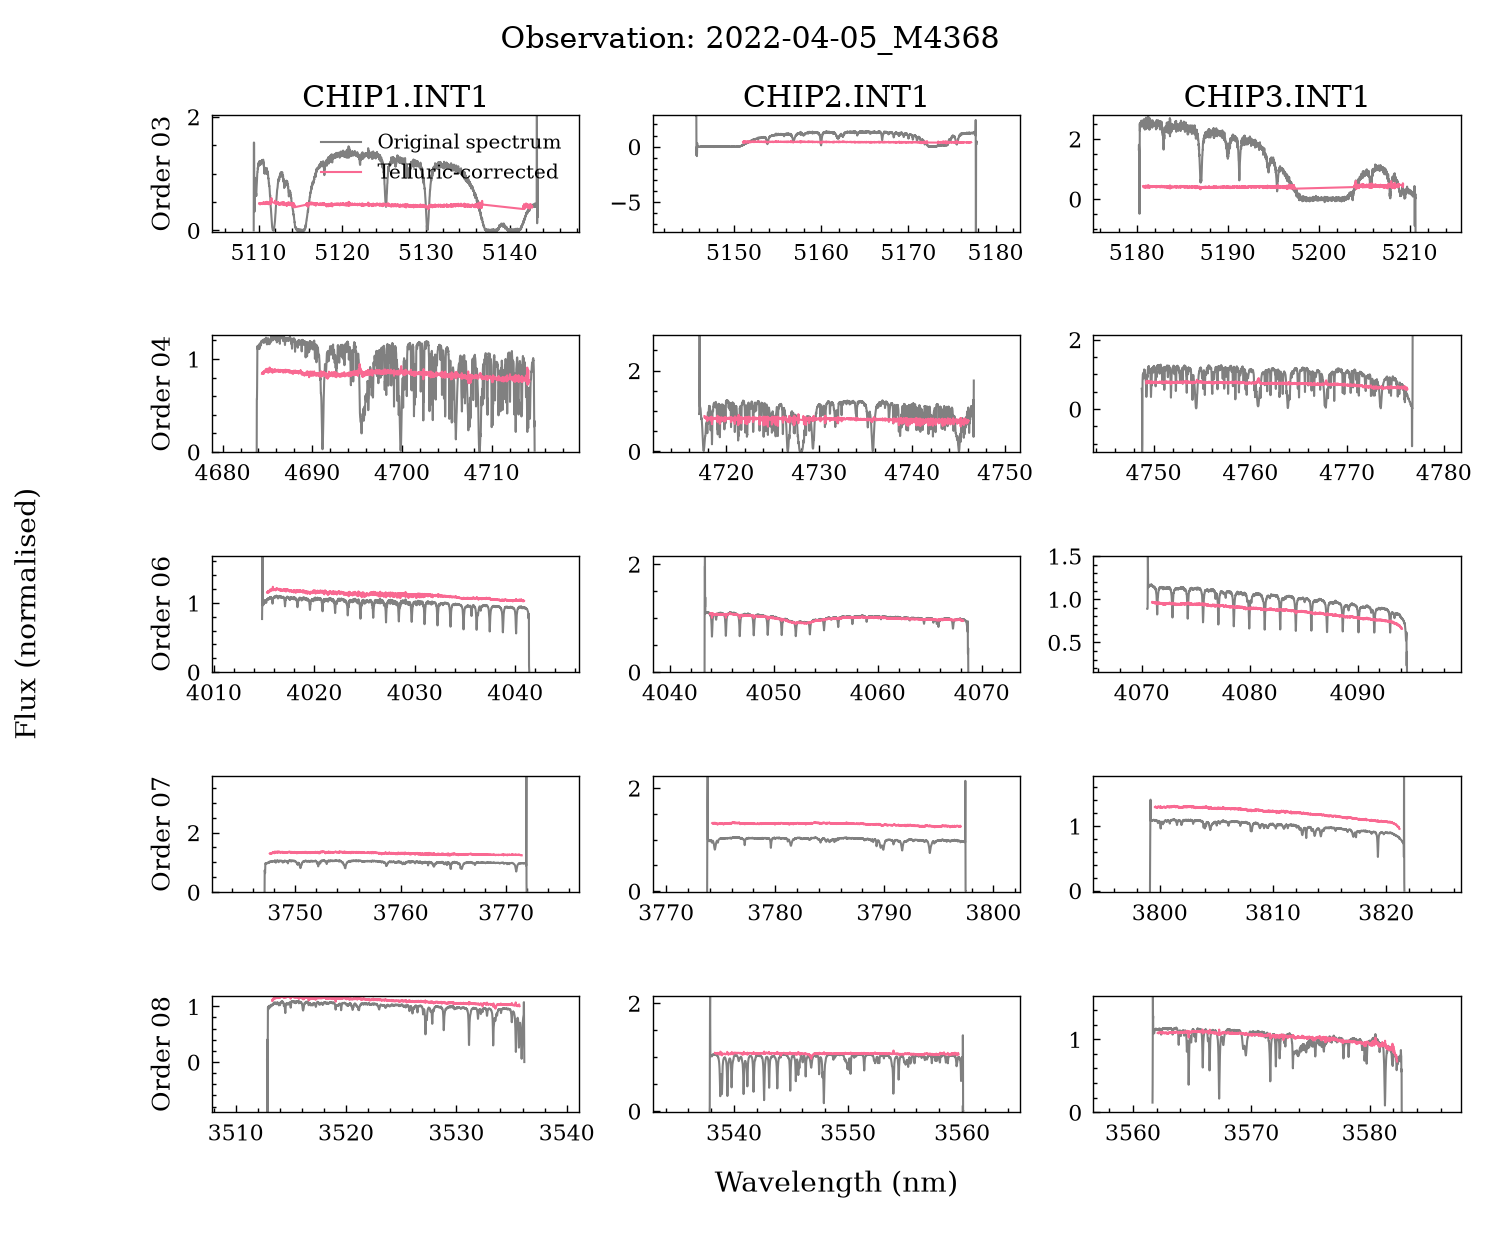

telluric range: 3513.31 to 5210.08 nm
telluric points: 29520
original data range: 3512.84 to 5210.66 nm
total wavelength points: 30671


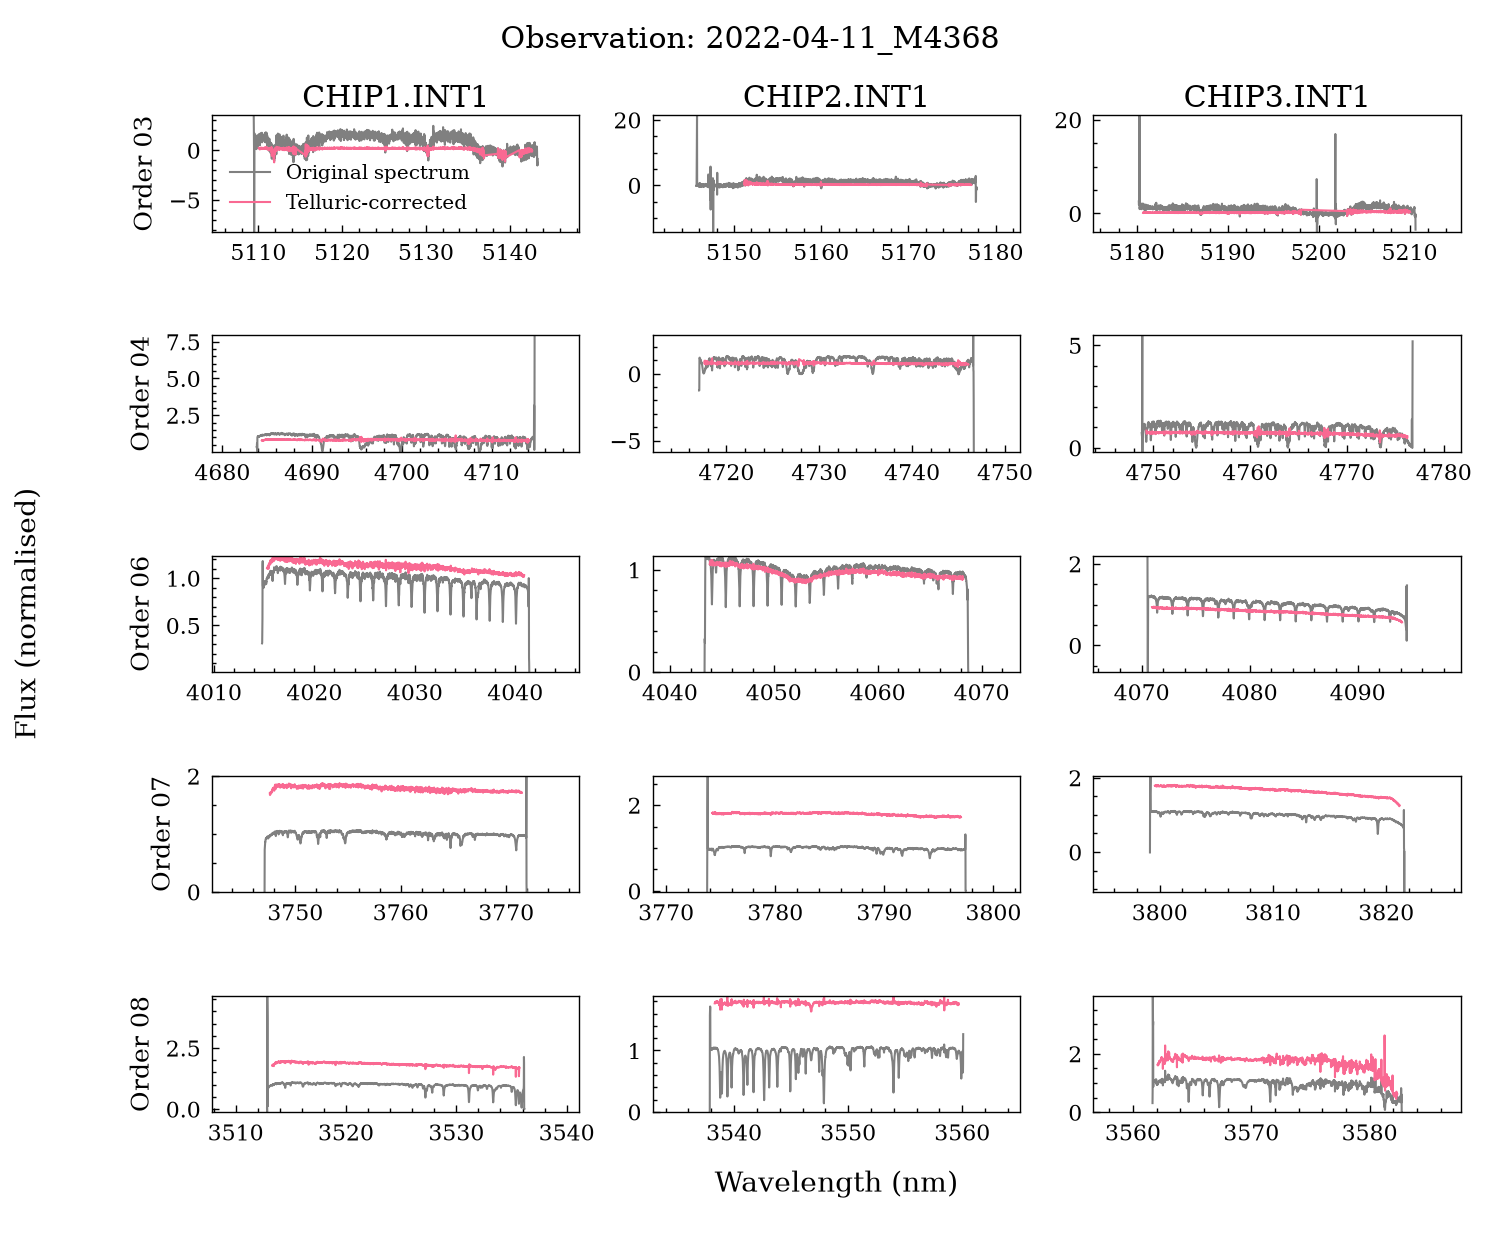

telluric range: 3470.90 to 5153.46 nm
telluric points: 29520
original data range: 3470.42 to 5154.09 nm
total wavelength points: 30682


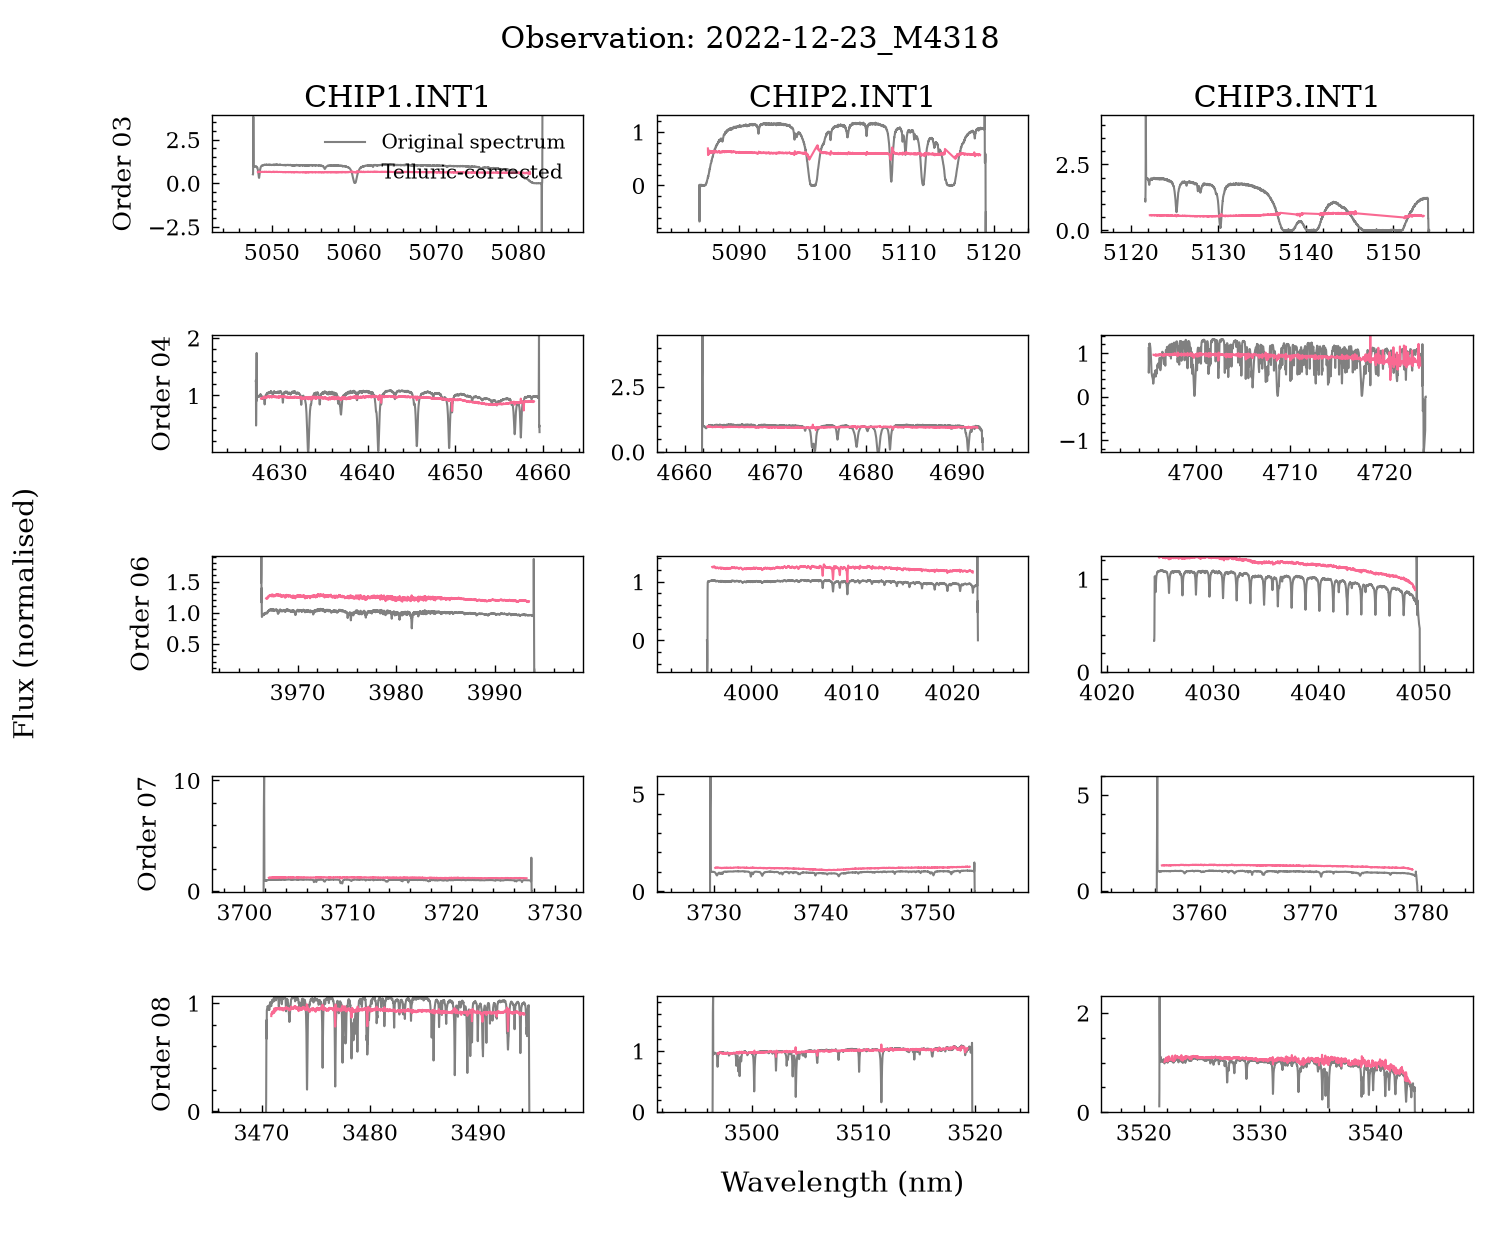

telluric range: 3470.91 to 5153.45 nm
telluric points: 27552
original data range: 3470.42 to 5154.07 nm
total wavelength points: 30679


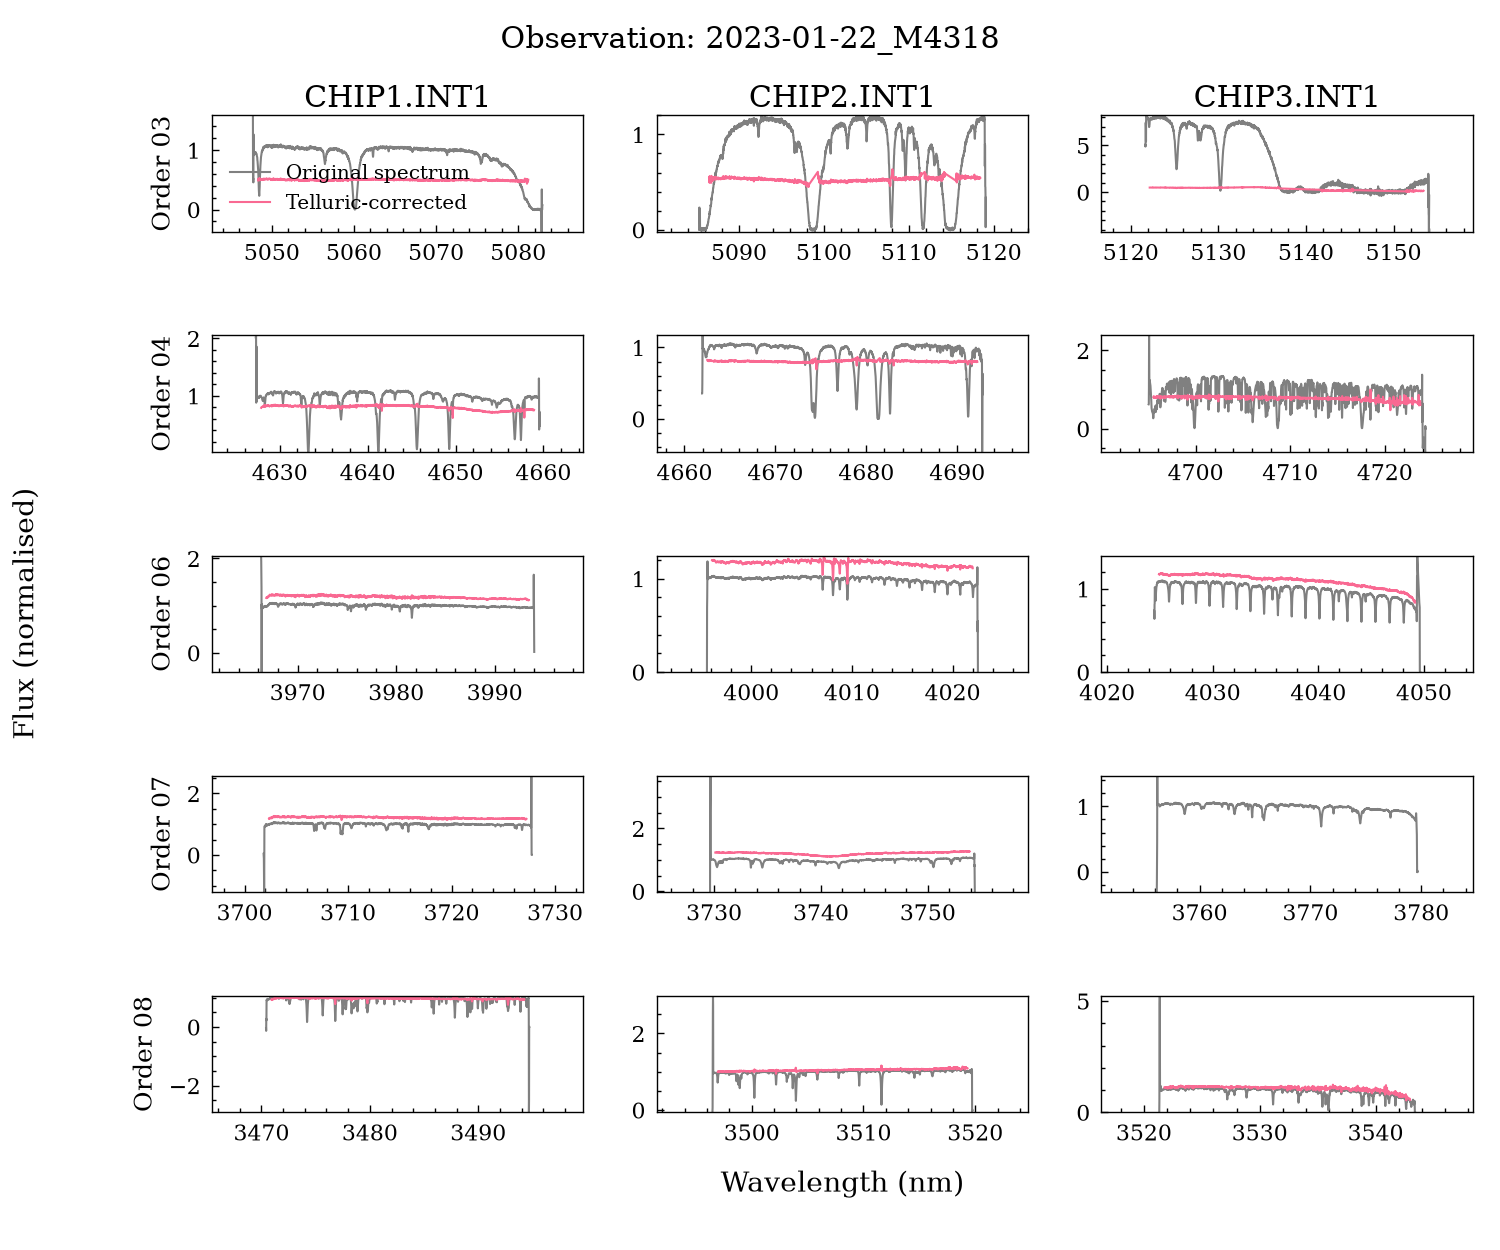

In [22]:
for f in dat_files_sorted:

    df = pd.read_csv(f, comment="#", names=["wavelength", "flux", "error"], delimiter=r'\s+')
    print(f'telluric range: {df["wavelength"].min():.2f} to {df["wavelength"].max():.2f} nm')
    print(f'telluric points: {len(df)}')
    date_dir = f.parent.parent.name
    original_file = "/srv/local/anba6163/Clean_Data/" + date_dir + "/extr/cr2res_obs_nodding_extracted_combined.fits"

    orders = []

    with fits.open(original_file) as hdul:
        for hdu in hdul:
            if hdu.data is None or not hdu.name.startswith("CHIP"):
                continue

            columns = set(hdu.columns.names)

            for wl_col in sorted(c for c in columns if c.endswith("_WL")):

                order_id = wl_col.removesuffix("_01_WL")
                spec_col = f"{order_id}_01_SPEC"

                if spec_col not in columns:
                    continue

                orders.append(
                    (
                        hdu.name,
                        order_id,
                        np.asarray(hdu.data[wl_col], dtype=float).copy(),
                        np.asarray(hdu.data[spec_col], dtype=float).copy(),
                    )
                )

    if not orders:
        raise ValueError(f"No wavelength/spectrum orders found in {original_file}")

    corrected_wavelength = df["wavelength"].to_numpy(dtype=float)

    corrected_flux = df["flux"].to_numpy(dtype=float)
    corrected_valid = (
        np.isfinite(corrected_wavelength) & np.isfinite(corrected_flux)
    )
    corrected_wavelength = corrected_wavelength[corrected_valid]
    corrected_flux = corrected_flux[corrected_valid]

    sort_idx = np.argsort(corrected_wavelength)
    corrected_wavelength = corrected_wavelength[sort_idx]
    corrected_flux = corrected_flux[sort_idx]

    norm_constant = np.nanmedian(corrected_flux)
    corrected_flux_norm = corrected_flux / norm_constant

    chips = sorted({chip_name for chip_name, _, _, _ in orders})

    orders_by_chip = {
        chip: [order for order in orders if order[0] == chip]
        for chip in chips
    }

    n_rows = max(len(chip_orders) for chip_orders in orders_by_chip.values())

    fig, axes = plt.subplots(
        n_rows,
        len(chips),
        figsize=(5 * len(chips), 2.5 * n_rows),
        squeeze=False,
        sharex=False,
        sharey=False,
    )

    mins = []
    maxs = []
    total_wl_length = []

    for col, chip in enumerate(chips):
        chip_orders = orders_by_chip[chip]

        for row, (_, order_id, original_wavelength, original_flux) in enumerate(chip_orders):
            ax = axes[row, col]

            valid = np.isfinite(original_wavelength) & np.isfinite(original_flux)
            wl = original_wavelength[valid]
            mins.append(wl.min())
            maxs.append(wl.max())
            total_wl_length.append(len(wl))
            flux = original_flux[valid]

            norm_constant_2 = np.nanmedian(flux)
            flux_norm = flux / norm_constant_2
            flux_norm = flux / np.abs(norm_constant_2)



            ax.plot(wl, flux_norm, color="grey", label="Original spectrum")

            if corrected_wavelength.size >= 2 and wl.size:
                in_order = (
                    (corrected_wavelength >= wl.min())
                    & (corrected_wavelength <= wl.max())
                )
                order_wavelength = corrected_wavelength[in_order]
                order_flux = corrected_flux_norm[in_order]

                if order_wavelength.size >= 2:
                    aligned = (wl >= order_wavelength.min()) & (
                        wl <= order_wavelength.max()
                    )
                    ax.plot(
                        wl[aligned],
                        np.interp(wl[aligned], order_wavelength, order_flux),
                        label="Telluric-corrected",
                    )

            if col == 0:
                ax.set_ylabel(f"Order {order_id}")


            if col == 0 and row == 0:
                ax.legend()

            if row == 0:
                ax.set_title(chip)


            if col == 1 and row == n_rows - 1:
                ax.text(
                    0.5, -0.5,
                    "Wavelength (nm)",
                    fontsize=20,
                    ha="center",
                    va="top",
                    transform=ax.transAxes,
                )

            if col == 0 and row == round(n_rows / 2):
                ax.text(
                    -0.5, 0.5,
                    "Flux (normalised)",
                    fontsize=20,
                    ha="center",
                    va="center",
                    rotation=90,
                    transform=ax.transAxes,
                )

            # ax.set_title(f"{chip} — order {order_id}")
            # ax.set_xlabel("Wavelength (nm)")
            # ax.set_ylabel("Flux (counts)")
            # ax.legend(loc="upper right")
            ax.set_xlim(wl.min()-5, wl.max()+5)

        for row in range(len(chip_orders), n_rows):
            axes[row, col].set_visible(False)

    print(f"original data range: {min(mins):.2f} to {max(maxs):.2f} nm")
    print(f"total wavelength points: {sum(total_wl_length)}")
    fig.suptitle(f"Observation: {date_dir}")
    fig.tight_layout()
    plt.show()



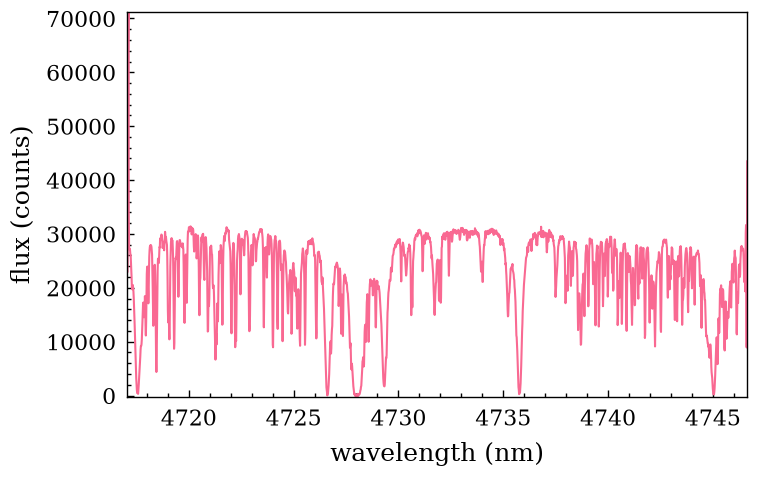

In [4]:
file = "/srv/local/anba6163/Clean_Data/2022-04-05_M4368/extr/cr2res_obs_nodding_extracted_combined.fits"

with fits.open(file) as hdul:
    chip1 = hdul["CHIP2.INT1"].data
    #print(chip1.columns)
    wavelength = chip1["04_01_WL"]
    flux = chip1["04_01_SPEC"]
    error = chip1["04_01_ERR"]
    
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(wavelength, flux, label='line')
ax.set_xlabel('wavelength (nm)')
ax.set_ylabel('flux (counts)')
#plt.legend()
# ax.set_xlim(4665, 4675)
# ax.set_ylim(0, 30000)
plt.show()

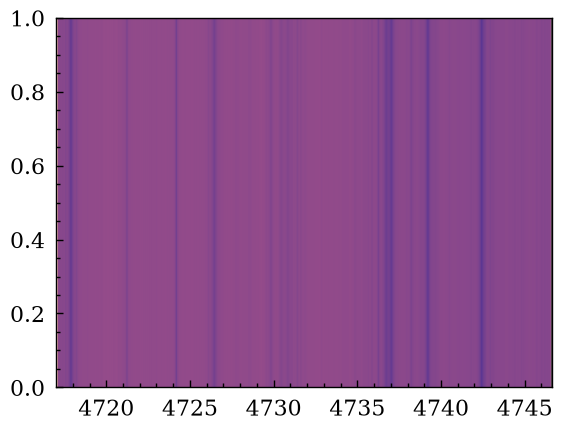

In [5]:
plt.imshow(chip1["07_01_SPEC"].reshape(1, -1), cmap = cmr.torch, aspect="auto", extent=[wavelength.min(), wavelength.max(), 0, 1])

In [6]:
newfile = "/srv/local/anba6163/Clean_Data/2025-10-01_M4519/extr/cr2res_obs_nodding_extractedA.fits"

with fits.open(newfile) as hdul:
    print(hdul.info())

Filename: /srv/local/anba6163/Clean_Data/2025-10-01_M4519/extr/cr2res_obs_nodding_extractedA.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU    1363   ()      
  1  CHIP1.INT1    1 BinTableHDU    138   2048R x 21C   [1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D]   
  2  CHIP2.INT1    1 BinTableHDU    138   2048R x 21C   [1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D]   
  3  CHIP3.INT1    1 BinTableHDU    138   2048R x 21C   [1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D]   
None


## Files to try:

- *obs_nodding_extracted_combined.fits (no star)
- *obs_nodding_extractedA/B.fits (no star)
- *obs_nodding_combinedA.fits (diff format, 2048x2048)
- *util_calib_flat_collapsed (diff format, 2048x2048, also data seems to be full of nans?)
- *util_calib_science_A_collapsed.fits 

41 fits files found
Filename: /srv/local/anba6163/Clean_Data/2022-04-05_M4368/extr/cr2res_obs_nodding_extracted_combined.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU    1390   ()      
  1  CHIP1.INT1    1 BinTableHDU    119   2048R x 15C   ['1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D']   
  2  CHIP2.INT1    1 BinTableHDU    119   2048R x 15C   [1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D]   
  3  CHIP3.INT1    1 BinTableHDU    119   2048R x 15C   [1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D]   


None


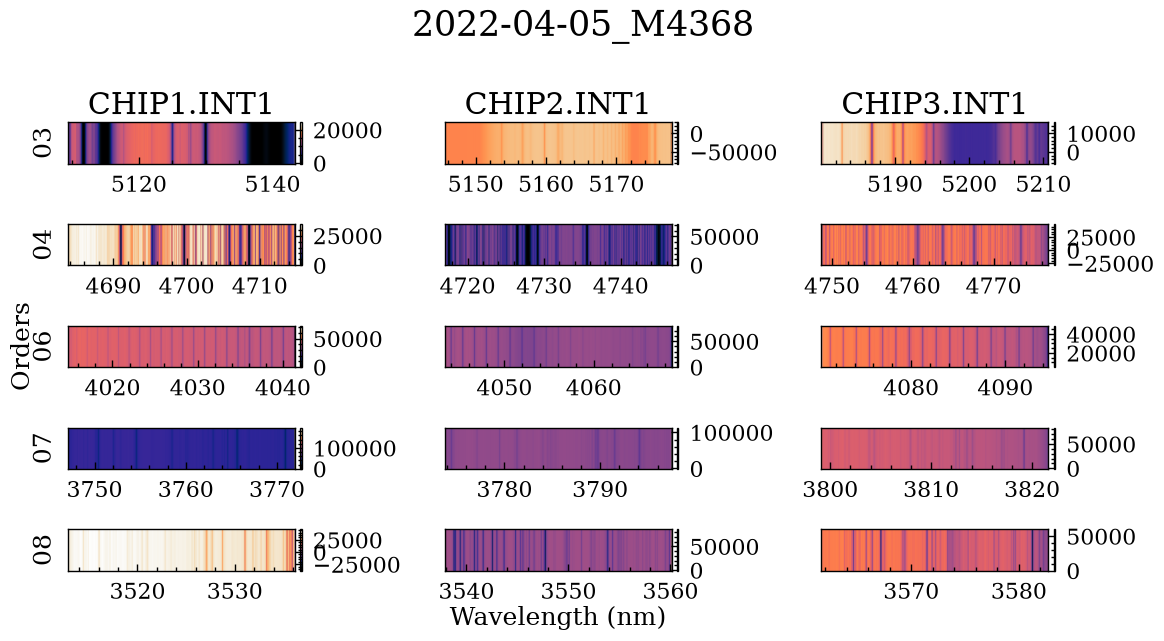

Filename: /srv/local/anba6163/Clean_Data/2022-04-11_M4368/extr/cr2res_obs_nodding_extracted_combined.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU    1390   ()      
  1  CHIP1.INT1    1 BinTableHDU    119   2048R x 15C   ['1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D']   
  2  CHIP2.INT1    1 BinTableHDU    119   2048R x 15C   [1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D]   
  3  CHIP3.INT1    1 BinTableHDU    119   2048R x 15C   [1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D]   
None


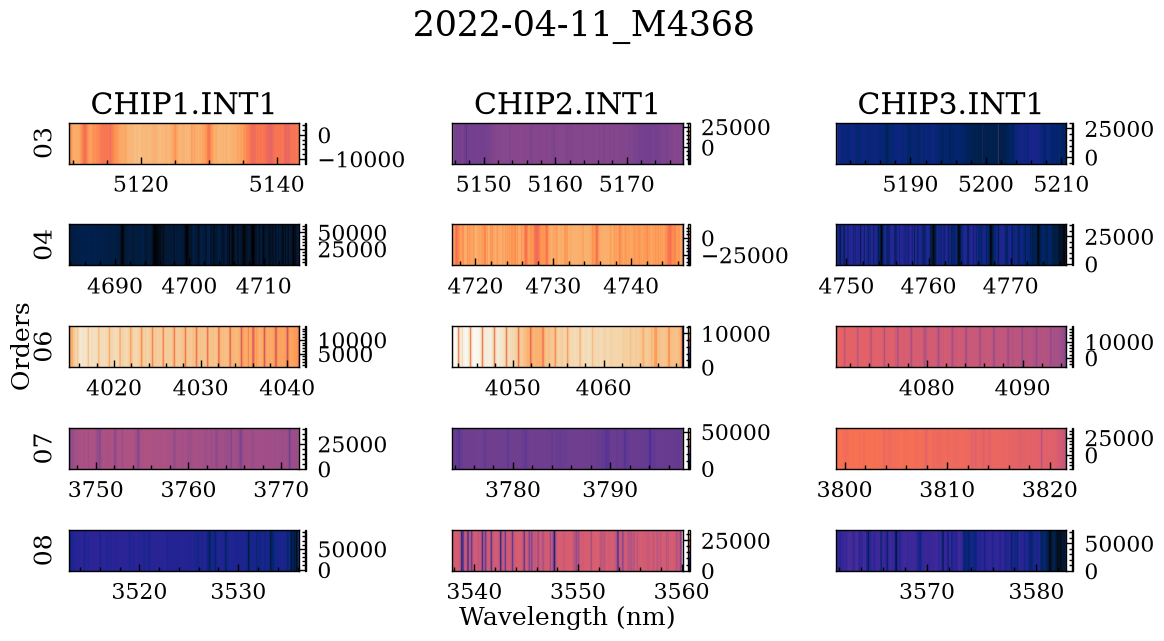

Filename: /srv/local/anba6163/Clean_Data/2022-11-29_L3262/extr/cr2res_obs_nodding_extracted_combined.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU    1422   ()      
  1  CHIP1.INT1    1 BinTableHDU    128   2048R x 18C   ['1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D']   
  2  CHIP2.INT1    1 BinTableHDU    128   2048R x 18C   [1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D]   
  3  CHIP3.INT1    1 BinTableHDU    128   2048R x 18C   [1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D]   
None


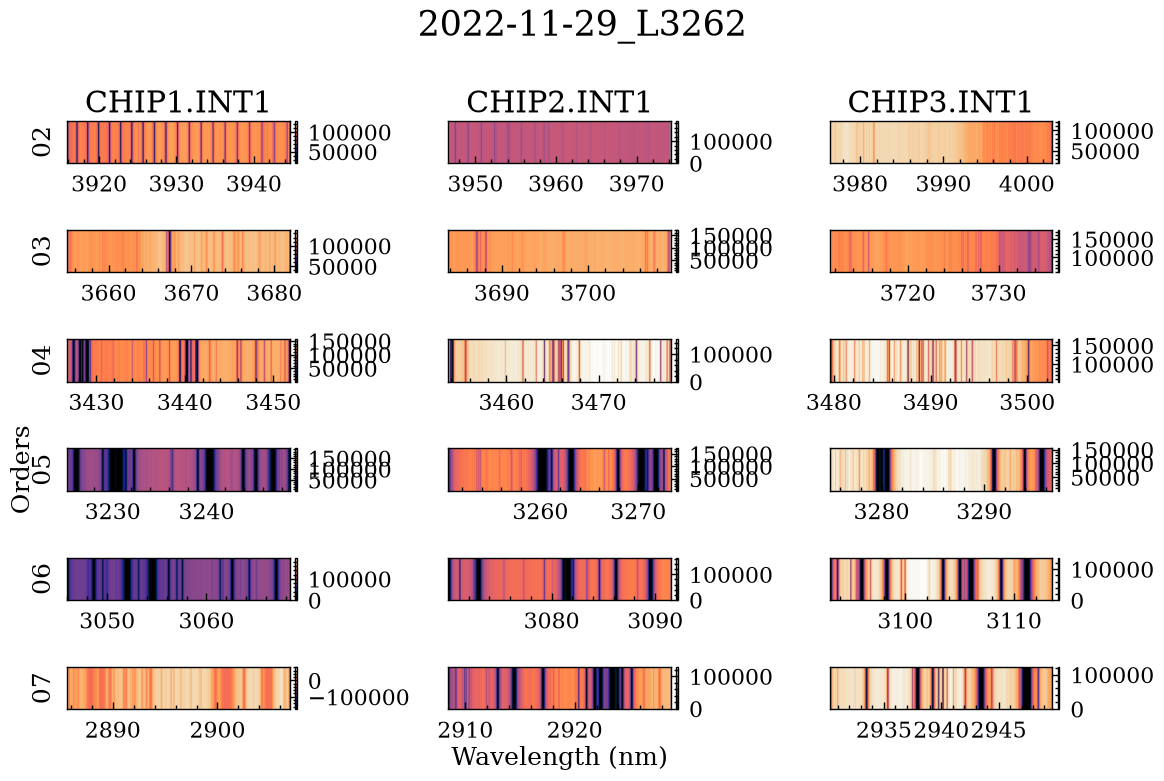

Filename: /srv/local/anba6163/Clean_Data/2022-11-29_L3262/extr/old/cr2res_obs_nodding_extracted_combined.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU    1422   ()      
  1  CHIP1.INT1    1 BinTableHDU    128   2048R x 18C   ['1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D']   
  2  CHIP2.INT1    1 BinTableHDU    128   2048R x 18C   [1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D]   
  3  CHIP3.INT1    1 BinTableHDU    128   2048R x 18C   [1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D]   
None


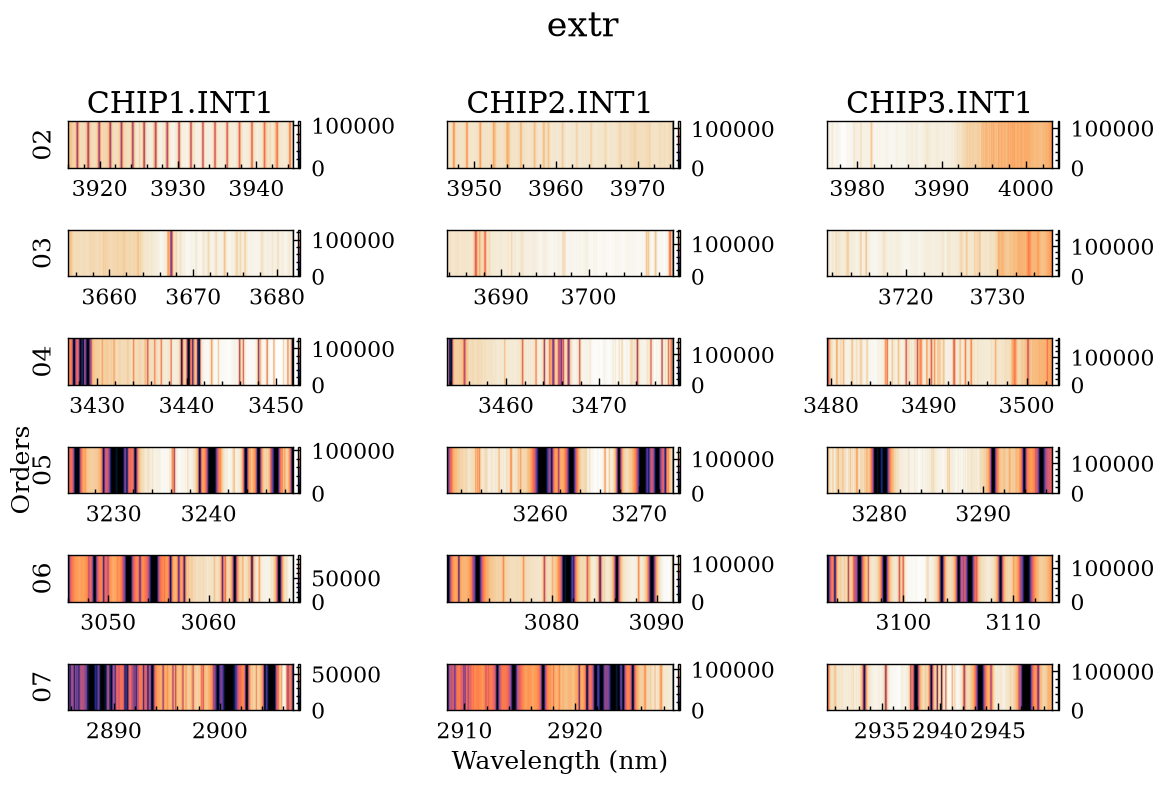

Filename: /srv/local/anba6163/Clean_Data/2022-12-23_L3262/extr/cr2res_obs_nodding_extracted_combined.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU    1430   ()      
  1  CHIP1.INT1    1 BinTableHDU    128   2048R x 18C   ['1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D']   
  2  CHIP2.INT1    1 BinTableHDU    128   2048R x 18C   [1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D]   
  3  CHIP3.INT1    1 BinTableHDU    128   2048R x 18C   [1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D]   
None


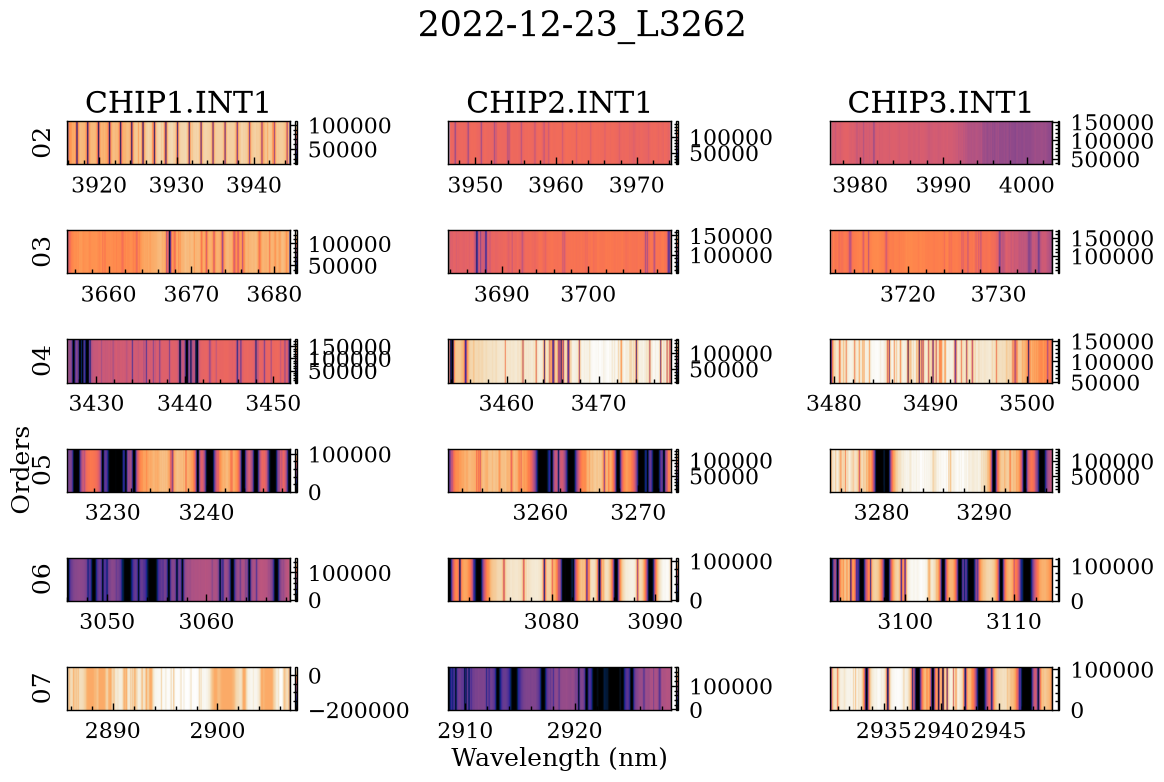

Filename: /srv/local/anba6163/Clean_Data/2022-12-23_L3262/extr/old/cr2res_obs_nodding_extracted_combined.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU    1430   ()      
  1  CHIP1.INT1    1 BinTableHDU    128   2048R x 18C   ['1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D']   
  2  CHIP2.INT1    1 BinTableHDU    128   2048R x 18C   [1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D]   
  3  CHIP3.INT1    1 BinTableHDU    128   2048R x 18C   [1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D]   
None


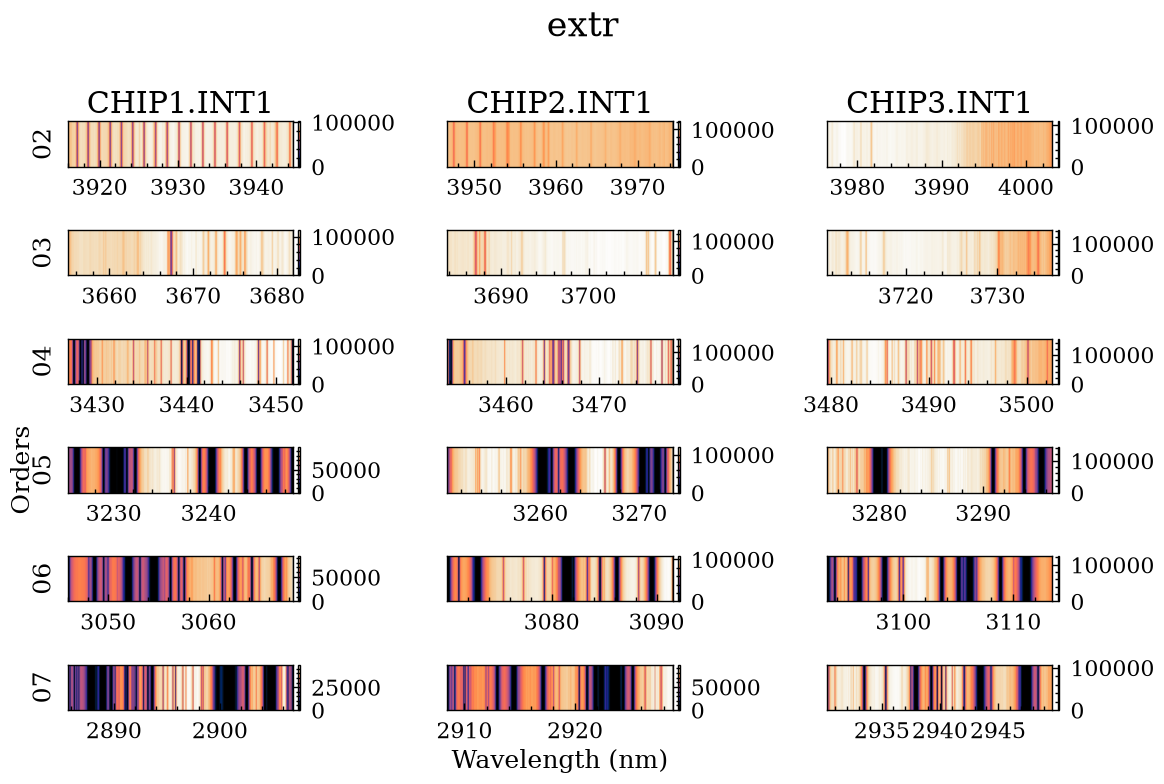

Filename: /srv/local/anba6163/Clean_Data/2022-12-23_M4318/extr/cr2res_obs_nodding_extracted_combined.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU    1354   ()      
  1  CHIP1.INT1    1 BinTableHDU    119   2048R x 15C   ['1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D']   
  2  CHIP2.INT1    1 BinTableHDU    119   2048R x 15C   [1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D]   
  3  CHIP3.INT1    1 BinTableHDU    119   2048R x 15C   [1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D]   
None


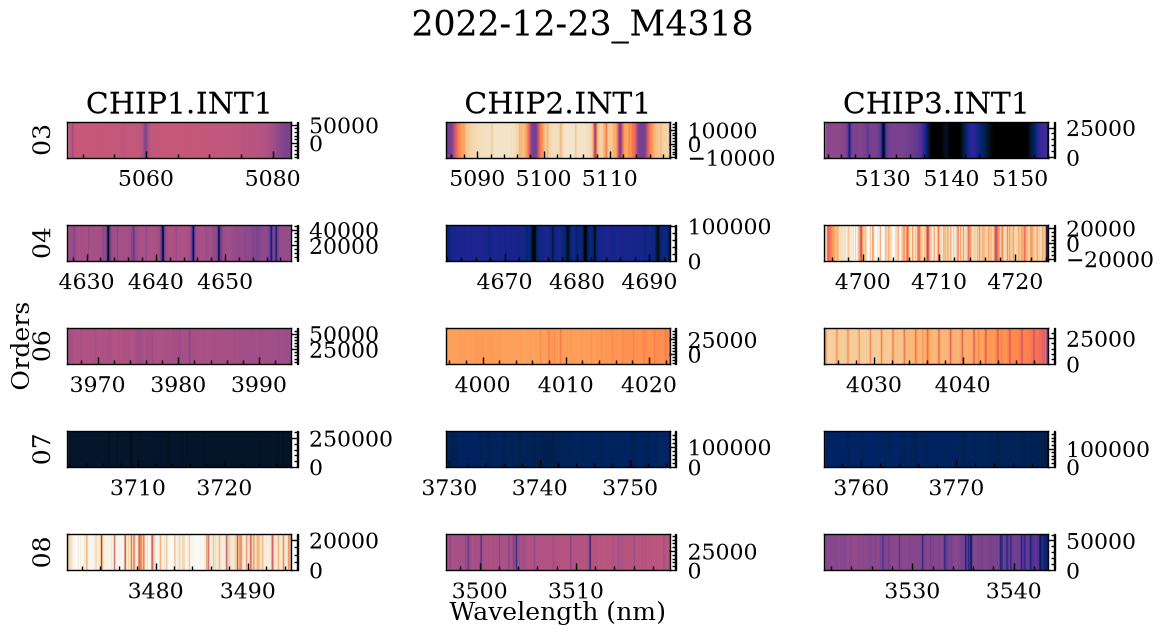

Filename: /srv/local/anba6163/Clean_Data/2022-12-23_M4318/extr/old/cr2res_obs_nodding_extracted_combined.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU    1354   ()      
  1  CHIP1.INT1    1 BinTableHDU    119   2048R x 15C   ['1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D', '1D']   
  2  CHIP2.INT1    1 BinTableHDU    119   2048R x 15C   [1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D]   
  3  CHIP3.INT1    1 BinTableHDU    119   2048R x 15C   [1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D]   
None


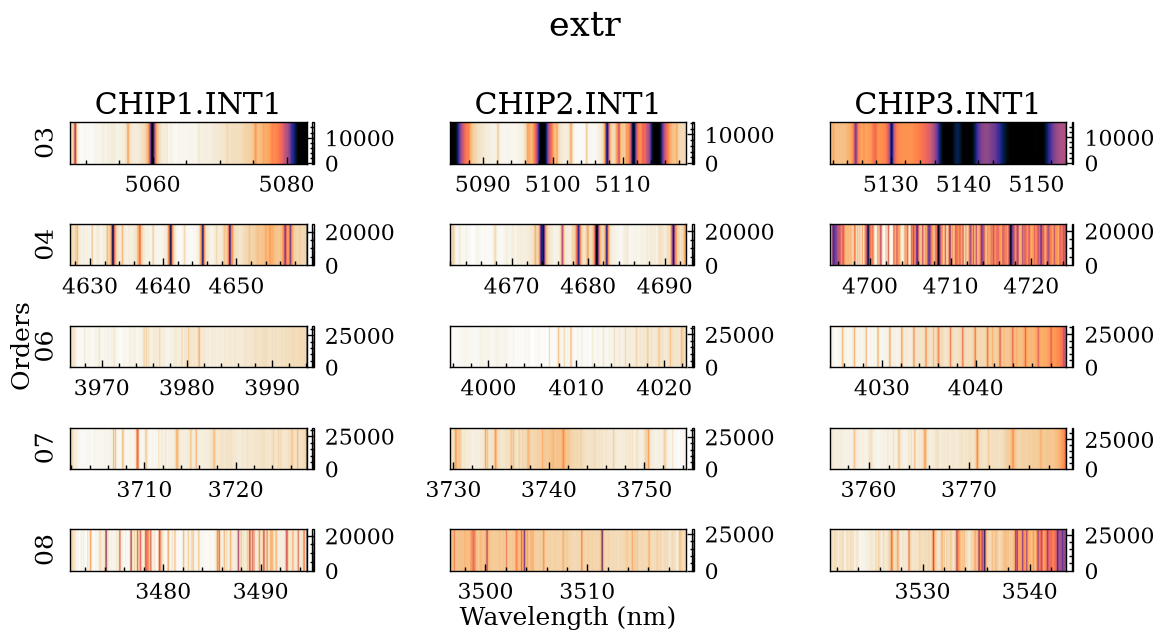

In [7]:
from pathlib import Path
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
import cmasher as cmr


base_dir = Path("/srv/local/anba6163/Clean_Data/")

fits_files = sorted(
    base_dir.rglob("cr2res_obs_nodding_extracted_combined.fits")
)

chips = [
    "CHIP1.INT1",
    "CHIP2.INT1",
    "CHIP3.INT1",
]
print(len(fits_files), "fits files found")

for file in fits_files[:8]:

    with fits.open(file) as hdul:

        data = hdul[chips[0]].data
        print(hdul.info())

        # ------------------------------------------------------------
        # Find the spectrum columns for each chip
        # ------------------------------------------------------------

        spec_columns = {}

        for chip in chips:
            data = hdul[chip].data

            spec_columns[chip] = [
                name for name in data.names
                if name.endswith("_SPEC")
            ]

            #print(f"{chip}: {spec_columns[chip]}")

        # Number of rows = number of orders
        n_orders = max(len(cols) for cols in spec_columns.values())

        # ------------------------------------------------------------
        # Create figure
        # ------------------------------------------------------------

        fig, axes = plt.subplots(
            n_orders,
            3,
            figsize=(12, 1.4 * n_orders),
            squeeze=False,
            sharex=False,
            sharey = True,
        )

        # ------------------------------------------------------------
        # Loop over chips
        # ------------------------------------------------------------

        for chip_index, chip in enumerate(chips):

            data = hdul[chip].data
            cols = spec_columns[chip]

            for i, spec_name in enumerate(cols):

                ax = axes[i, chip_index]

                # Spectrum
                spectrum = np.asarray(data[spec_name])

                # Find corresponding wavelength column
                wl_name = spec_name.replace("_SPEC", "_WL")
                wavelength = np.asarray(data[wl_name])

                # Get order identifier
                order = spec_name.removesuffix("_01_SPEC")

                # Mask extreme values
                # spectrum = np.asarray(data[spec_name], dtype=float)

                # low, high = np.nanpercentile(spectrum, [0.5, 99.5])

                # spectrum = np.ma.masked_outside(spectrum, low, high)

                # Plot 
                im = ax.imshow(
                    spectrum.reshape(1, -1),
                    cmap=cmr.torch,
                    aspect="auto",
                    origin="lower",
                    extent=[
                        wavelength.min(),
                        wavelength.max(),
                        0,
                        1,
                    ],
                )

                ax.set_yticks([])

                if chip_index == 0:
                    ax.set_ylabel(f"{order}")

                if i == 0:
                    ax.set_title(chip)


                if chip_index == 1 and i == n_orders - 1:
                    ax.text(
                        0.5, -0.86,
                        "Wavelength (nm)",
                        ha="center",
                        va="top",
                        transform=ax.transAxes,
                    )

                if chip_index == 0 and i == round(n_orders / 2):
                    ax.text(
                        -0.2, 0.5,
                        "Orders",
                        ha="center",
                        va="center",
                        rotation=90,
                        transform=ax.transAxes,
                    )

                # ----------------------------------------------------
                # Colorbar for each chip
                # ----------------------------------------------------

                fig.colorbar(
                    im,
                    ax=ax,
                    pad=0.02,
                    aspect=30,
                )

            # Hide unused axes if this chip has fewer orders
            for i in range(len(cols), n_orders):
                axes[i, chip_index].set_visible(False)

        # ------------------------------------------------------------
        # Figure title
        # ------------------------------------------------------------

        fig.suptitle(
            file.parent.parent.name,
            fontsize=25,
            y=0.99,
        )



        fig.tight_layout()


        plt.show()